# Project TuneCraft: Production-Ready LoRA Fine-Tuning

## Objective

Build and evaluate a complete parameter-efficient fine-tuning pipeline for **TinyLlama-1.1B-Chat** using **LoRA** and **Databricks Dolly-15K**. The notebook is designed for a Google Colab T4 runtime and records evidence for every grading pillar.

## Evaluation map

1. **Base Model Evaluation (20):** deterministic baseline responses and held-out loss.
2. **Dataset Engineering (20):** validated conversational formatting, deterministic sampling, and token-length analysis.
3. **LoRA Configuration & Injection (20):** attention-only adapters, module inspection, and a hard `<1%` trainable-parameter check.
4. **Supervised Fine-Tuning (20):** T4-safe SFT configuration, baseline evaluation, training metrics, and learning diagnostics.
5. **Adapter Persistence & Evaluation (20):** lightweight adapter save, size verification, qualitative comparison, held-out perplexity, and clean reload test.

## Case-study decision

LoRA updates only `q_proj` and `v_proj`, sharply reducing trainable parameters and artifact size while preserving the frozen 1.1B-parameter base model. Fixed seeds and greedy decoding make the before/after comparison reproducible.

## Prerequisites

- Runtime: **GPU** (T4 is sufficient).
- Run from top to bottom in a fresh Colab session.
- Expected runtime depends on Colab load; the full training set is 1,000 examples.

---
## Part 0: Colab-Safe Setup

> **Important:** Colab already provides a CUDA-compatible PyTorch and torchvision pair. The installation cell intentionally does not install or upgrade either package. If an earlier run changed them, use **Runtime > Disconnect and delete runtime** before running this notebook again.

In [49]:
# Colab provides a CUDA-matched torch/torchvision pair. Do NOT upgrade either one.
# TorchAO is optional and unused here; older Colab builds conflict with current PEFT.
%pip uninstall -q -y torchao
# Installing the Hugging Face packages together lets pip select a mutually compatible stack.
%pip install -q -U --upgrade-strategy only-if-needed "huggingface-hub==1.33.0" "transformers==5.20.1" "trl==1.16.0" "peft==0.21.2" "datasets==5.1.0" "accelerate==1.15.0" safetensors

In [50]:
import gc
import importlib.metadata as metadata
import importlib.util
import inspect
import json
import math
import os
import random
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

# Fail early with a useful message if an earlier pip command broke Colab's CUDA pair.
if importlib.util.find_spec("torchvision") is not None:
    try:
        import torchvision
    except (ImportError, RuntimeError) as exc:
        raise RuntimeError(
            "PyTorch and torchvision are incompatible in this runtime. In Colab, use "
            "Runtime > Disconnect and delete runtime, reconnect to a T4, and run the "
            "updated notebook from the first cell. Do not pip-install torch or torchvision."
        ) from exc
from IPython.display import display
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import LoraConfig, PeftModel, get_peft_model
from trl import SFTConfig, SFTTrainer

from transformers import set_seed

for package in ["torch", "torchvision", "transformers", "trl", "peft", "datasets", "accelerate", "huggingface-hub"]:
    if importlib.util.find_spec(package.replace("-", "_")) is None:
        continue
    print(f"{package}: {metadata.version(package)}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB")
    print(f"CUDA compute capability: {torch.cuda.get_device_capability(0)}")
else:
    raise RuntimeError("A CUDA GPU is required. In Colab select Runtime > Change runtime type > T4 GPU.")

torch: 2.11.0+cu130
torchvision: 0.26.0+cu130
transformers: 5.20.1
trl: 1.16.0
peft: 0.21.2
datasets: 5.1.0
accelerate: 1.15.0
huggingface-hub: 1.33.0
CUDA available: True
GPU: Tesla T4
GPU memory: 14.6 GB
CUDA compute capability: (7, 5)


### Utility functions (provided)

In [51]:
def clear_memory():
    """Free GPU memory between experiments."""
    gc.collect()
    torch.cuda.empty_cache()
    if torch.cuda.is_available():
        print(f"GPU allocated: {torch.cuda.memory_allocated() / 1024**3:.2f} GB")
        print(f"GPU reserved:  {torch.cuda.memory_reserved() / 1024**3:.2f} GB")


def trainable_parameter_stats(model):
    """Return trainable, total, and trainable percentage."""
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    return trainable, total, 100 * trainable / total


def print_trainable_params(model):
    """Display trainable vs total parameter counts."""
    trainable, total, percentage = trainable_parameter_stats(model)
    print(f"Trainable parameters: {trainable:>12,}  ({percentage:.4f}%)")
    print(f"Total parameters:     {total:>12,}")


def generate_response(model, tokenizer, prompt, generation_settings=None):
    """Generate deterministically so base and tuned outputs are comparable."""
    settings = dict(GENERATION_SETTINGS if generation_settings is None else generation_settings)
    model.eval()
    messages = [{"role": "user", "content": prompt}]
    input_text = tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)
    inputs = tokenizer(input_text, return_tensors="pt").to(model.device)
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=inputs["input_ids"].shape[1] + settings["max_new_tokens"],
            do_sample=settings["do_sample"],
            pad_token_id=tokenizer.pad_token_id,
        )
    response = tokenizer.decode(outputs[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
    return response.strip()


def response_diagnostics(response):
    """Simple transparent indicators; human review remains the quality authority."""
    sentences = [s for s in re.split(r"(?<=[.!?])\s+", response.strip()) if s]
    return {"words": len(response.split()), "sentences": len(sentences), "non_empty": bool(response.strip())}

---
## Stage 1: Configuration and Reproducibility

### Task 1: Define all hyperparameters

Set the following configuration variables:

| Variable | Value |
|---|---|
| `MODEL_NAME` | `"TinyLlama/TinyLlama-1.1B-Chat-v1.0"` |
| `DATASET_NAME` | `"databricks/databricks-dolly-15k"` |
| `NUM_TRAIN_SAMPLES` | `1000` |
| `MAX_SEQ_LENGTH` | `512` |
| `LORA_R` | `8` |
| `LORA_ALPHA` | `16` |
| `LORA_DROPOUT` | `0.05` |
| `LORA_TARGET_MODULES` | `["q_proj", "v_proj"]` (attention only) |
| `LEARNING_RATE` | `2e-4` |
| `NUM_EPOCHS` | `1` |
| `BATCH_SIZE` | `4` |
| `GRAD_ACCUM_STEPS` | `4` |
| `OUTPUT_DIR` | `"./sft-lora-tinyllama"` |

In [52]:
MODEL_NAME = "TinyLlama/TinyLlama-1.1B-Chat-v1.0"
DATASET_NAME = "databricks/databricks-dolly-15k"
NUM_TRAIN_SAMPLES = 1000
MAX_SEQ_LENGTH = 512
LORA_R, LORA_ALPHA, LORA_DROPOUT = 8, 16, 0.05
LORA_TARGET_MODULES = ["q_proj", "v_proj"]
LEARNING_RATE, NUM_EPOCHS = 2e-4, 1
BATCH_SIZE, GRAD_ACCUM_STEPS = 4, 4
NUM_EVAL_SAMPLES = 100
SEED = 42
OUTPUT_DIR = "./sft-lora-tinyllama"
ADAPTER_DIR = os.path.join(OUTPUT_DIR, "final-adapter")
EFFECTIVE_BATCH_SIZE = BATCH_SIZE * GRAD_ACCUM_STEPS
GENERATION_SETTINGS = {"max_new_tokens": 160, "do_sample": False}
random.seed(SEED); np.random.seed(SEED); set_seed(SEED)
print(f"Effective batch size: {EFFECTIVE_BATCH_SIZE}")

Effective batch size: 16


---
## Stage 2: Base Model Evaluation

### Task 2: Load the tokenizer and base model

1. Load the tokenizer from `MODEL_NAME`.
2. If the tokenizer has no pad token, set it to the eos token.
3. Load the model in `float16` with `device_map="auto"`.
4. Print the total parameter count.

In [53]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float16, device_map="auto")
model.config.pad_token_id = tokenizer.pad_token_id
base_parameter_count = sum(p.numel() for p in model.parameters())
assert tokenizer.chat_template, "TinyLlama chat template is required."
assert tokenizer.pad_token_id is not None, "A pad token is required for batching."
print(f"Total parameters: {base_parameter_count:,}")
print(f"Model dtype: {next(model.parameters()).dtype}; device: {model.device}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Total parameters: 1,100,048,384
Model dtype: torch.float16; device: cuda:0


---
### 2.1 Deterministic baseline generation

### Task 3: Generate responses from the base model

Use the provided `generate_response` function with these test prompts:
1. `"Explain what a neural network is in 2-3 sentences."`
2. `"What are three tips for better sleep?"`

Store the responses in a list called `base_responses` for later comparison.

In [54]:
test_prompts = (
    "Explain what a neural network is in 2-3 sentences.",
    "What are three tips for better sleep?",
)
baseline_prompt_fingerprint = tuple(test_prompts)
baseline_generation_settings = dict(GENERATION_SETTINGS)
base_responses = [
    generate_response(model, tokenizer, p, baseline_generation_settings) for p in test_prompts
]
assert len(base_responses) == len(baseline_prompt_fingerprint)
for prompt, response in zip(test_prompts, base_responses):
    print(f"\nPROMPT: {prompt}\nBASE RESPONSE: {response}")
    print("Diagnostics:", response_diagnostics(response))


PROMPT: Explain what a neural network is in 2-3 sentences.
BASE RESPONSE: A neural network is a type of artificial intelligence (AI) system that mimics the way the human brain processes information. It consists of a series of interconnected nodes (neurons) that receive input from other nodes and process and output information based on the input. Neural networks can be used for a variety of tasks, including image recognition, speech recognition, and machine translation. They are often trained using supervised learning, where the output of one node is used as input for the next node in the network. Neural networks are often used in deep learning, which involves training the network on large datasets to learn complex patterns and relationships.
Diagnostics: {'words': 108, 'sentences': 5, 'non_empty': True}

PROMPT: What are three tips for better sleep?
BASE RESPONSE: 1. Create a sleep-conducive environment: Make sure your bedroom is cool, dark, and quiet. Avoid using electronic devices b

---
## Stage 3: Dataset Engineering

### Task 4: Load and format the Dolly dataset

The Dolly dataset has columns: `instruction`, `context`, `response`, `category`.

1. Load the dataset (`split="train"`).
2. Write a function `format_dolly_to_chat(example)` that converts each example to:
   ```python
   {"messages": [
       {"role": "user", "content": <instruction + context if present>},
       {"role": "assistant", "content": <response>}
   ]}
   ```
   If `context` is non-empty, concatenate it to the instruction with a newline separator.
3. Shuffle with `seed=42`, select `NUM_TRAIN_SAMPLES` examples, and apply the formatting function.
4. Print the size of the formatted dataset and one example.



```
Example formatted entry:
{'messages': [{'content': 'Who were the children of the legendary Garth Greenhand, the High King of the First Men in the series A Song of Ice and Fire?', 'role': 'user'}, {'content': 'Garth the Gardener, John the Oak, Gilbert of the Vines, Brandon of the Bloody Blade, Foss the Archer, Owen Oakenshield, Harlon the Hunter, Herndon of the Horn, Bors the Breaker, Florys the Fox, Maris the Maid, Rose of the Red Lake, Ellyn Ever Sweet, Rowan Gold-Tree', 'role': 'assistant'}]}
```



In [55]:
dolly = load_dataset(DATASET_NAME, split="train")
required_columns = {"instruction", "context", "response", "category"}
assert required_columns.issubset(dolly.column_names), f"Missing columns: {required_columns - set(dolly.column_names)}"
print(f"Raw rows: {len(dolly):,}; columns: {dolly.column_names}")
print("Category distribution:")
print(pd.Series(dolly["category"]).value_counts().to_string())

def format_dolly_to_chat(example):
    instruction, context = (example["instruction"] or "").strip(), (example["context"] or "").strip()
    user_content = instruction + (f"\n{context}" if context else "")
    return {"messages": [{"role": "user", "content": user_content}, {"role": "assistant", "content": (example["response"] or "").strip()}]}
shuffled = dolly.shuffle(seed=SEED)
assert len(shuffled) >= NUM_TRAIN_SAMPLES + NUM_EVAL_SAMPLES
train_raw = shuffled.select(range(NUM_TRAIN_SAMPLES))
eval_raw = shuffled.select(range(NUM_TRAIN_SAMPLES, NUM_TRAIN_SAMPLES + NUM_EVAL_SAMPLES))
train_instruction_set = {(instruction or "").strip() for instruction in train_raw["instruction"]}
assert not train_instruction_set.intersection(test_prompts), "An evaluation prompt appears verbatim in the training split."
print("Evaluation prompt leakage check passed: no exact prompt appears in the training split.")
formatted_dataset = train_raw.map(format_dolly_to_chat, remove_columns=train_raw.column_names, desc="Formatting train set")
eval_dataset = eval_raw.map(format_dolly_to_chat, remove_columns=eval_raw.column_names, desc="Formatting eval set")
assert len(formatted_dataset) == NUM_TRAIN_SAMPLES and len(eval_dataset) == NUM_EVAL_SAMPLES
assert all(len(row["messages"]) == 2 for row in formatted_dataset.select(range(20)))
assert all(row["messages"][0]["role"] == "user" and row["messages"][1]["role"] == "assistant" for row in formatted_dataset.select(range(20)))
print(f"Formatted train/eval examples: {len(formatted_dataset)}/{len(eval_dataset)}")
print(formatted_dataset[0])

sample_texts = [tokenizer.apply_chat_template(x["messages"], tokenize=False) for x in formatted_dataset.select(range(100))]
sample_lengths = [len(tokenizer(text, add_special_tokens=False, verbose=False)["input_ids"]) for text in sample_texts]
print(pd.Series(sample_lengths).describe(percentiles=[0.5, 0.9, 0.95, 0.99]).round(1))
print(f"Sample truncation rate at {MAX_SEQ_LENGTH} tokens: {np.mean(np.array(sample_lengths) > MAX_SEQ_LENGTH):.1%}")

Raw rows: 15,011; columns: ['instruction', 'context', 'response', 'category']
Category distribution:
open_qa                   3742
general_qa                2191
classification            2136
closed_qa                 1773
brainstorming             1766
information_extraction    1506
summarization             1188
creative_writing           709
Evaluation prompt leakage check passed: no exact prompt appears in the training split.
Formatted train/eval examples: 1000/100
{'messages': [{'role': 'user', 'content': 'Who were the children of the legendary Garth Greenhand, the High King of the First Men in the series A Song of Ice and Fire?'}, {'role': 'assistant', 'content': 'Garth the Gardener, John the Oak, Gilbert of the Vines, Brandon of the Bloody Blade, Foss the Archer, Owen Oakenshield, Harlon the Hunter, Herndon of the Horn, Bors the Breaker, Florys the Fox, Maris the Maid, Rose of the Red Lake, Ellyn Ever Sweet, Rowan Gold-Tree'}]}
count     100.0
mean      273.4
std       503.5
m

### Sequence-length rationale

`MAX_SEQ_LENGTH=512` is a deliberate compute-quality trade-off for LoRA fine-tuning on a Colab T4. The sampled length analysis shows that about 92% of examples fit without truncation, while a longer context would increase GPU-memory use and training time. The observed 8% sample truncation rate is therefore accepted and reported rather than hidden.

---
## Stage 4: LoRA Configuration and Injection

### Task 5: Create the LoRA config and inspect trainable parameters

1. Create a `LoraConfig` using the hyperparameters from Task 1. Set `bias="none"` and `task_type="CAUSAL_LM"`.
2. Apply it to the model with `get_peft_model`.
3. Use `print_trainable_params` to display the trainable vs total parameters.
4. Print the LoRA-wrapped structure of one attention layer (e.g., `q_proj` of layer 0).

In [56]:
lora_config = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, target_modules=LORA_TARGET_MODULES, bias="none", task_type="CAUSAL_LM")
model = get_peft_model(model, lora_config)
print_trainable_params(model)
trainable_count, peft_total_count, trainable_percentage = trainable_parameter_stats(model)
assert 0 < trainable_percentage < 1.0, f"Expected <1% trainable parameters, got {trainable_percentage:.4f}%"
trainable_names = [name for name, parameter in model.named_parameters() if parameter.requires_grad]
assert trainable_names and all(any(target in name for target in LORA_TARGET_MODULES) for name in trainable_names)
print(f"Trainable tensors: {len(trainable_names)}; target modules: {LORA_TARGET_MODULES}")
q_proj_modules = [(name, module) for name, module in model.named_modules() if name.endswith("layers.0.self_attn.q_proj")]
assert q_proj_modules, "Could not locate layer 0 q_proj after LoRA injection."
q_proj_name, q_proj_module = q_proj_modules[0]
print(f"Layer 0 q_proj after injection ({q_proj_name}):")
print(q_proj_module)

Trainable parameters:    1,126,400  (0.1023%)
Total parameters:     1,101,174,784
Trainable tensors: 88; target modules: ['q_proj', 'v_proj']
Layer 0 q_proj after injection (base_model.model.model.layers.0.self_attn.q_proj):
lora.Linear(
  (base_layer): Linear(in_features=2048, out_features=2048, bias=False)
  (lora_dropout): ModuleDict(
    (default): Dropout(p=0.05, inplace=False)
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=2048, out_features=8, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=8, out_features=2048, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


---
## Stage 5: Supervised Fine-Tuning

### Task 6: Set up SFTTrainer and run training

1. Delete the PEFT-wrapped model and call `clear_memory()`. Reload the base model fresh (SFTTrainer applies LoRA itself via `peft_config`).
2. Create an `SFTConfig` with the hyperparameters from Task 1. Include:
   - Cosine LR scheduler, warmup ratio 0.03, weight decay 0.01
   - `gradient_checkpointing=True`
   - bf16 if supported, else fp16
   - `max_length=MAX_SEQ_LENGTH`
   - Logging every 10 steps
3. Create an `SFTTrainer` with the model, training args, dataset, tokenizer, and `peft_config`.
4. Call `trainer.train()` and print the final loss.

GPU allocated: 2.08 GB
GPU reserved:  4.12 GB


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Training precision: FP16 (compute capability 7.5)
Optimizer steps: 63; warmup steps: 2 (~3%)
Applied SFTConfig fields: ['bf16', 'data_seed', 'eval_strategy', 'fp16', 'gradient_accumulation_steps', 'gradient_checkpointing', 'gradient_checkpointing_kwargs', 'include_num_input_tokens_seen', 'learning_rate', 'logging_first_step', 'logging_steps', 'logging_strategy', 'lr_scheduler_type', 'max_length', 'num_train_epochs', 'output_dir', 'packing', 'per_device_eval_batch_size', 'per_device_train_batch_size', 'report_to', 'save_strategy', 'seed', 'warmup_steps', 'weight_decay']
Gradient checkpointing verified: True
Hardware-conditional mixed precision verified: FP16
Trainable parameters:    1,126,400  (0.1023%)
Total parameters:     1,101,174,784


Training Loss,Validation Loss,Epoch,Entropy,Mean Token Accuracy,Num Tokens,Input Tokens Seen
No log,2.246403,0,1.521407,0.572959,0.000000,0


Baseline held-out loss: 2.2464


Epoch,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens,Input Tokens Seen
1,1.726608,1.754545,1.763926,0.619804,191522.000000,351860


Training Loss,Validation Loss,Epoch,Entropy,Mean Token Accuracy,Num Tokens,Input Tokens Seen
1.726608,1.754545,1,1.763926,0.619804,191522.000000,351860


,step,epoch,loss,eval_loss,learning_rate,grad_norm,num_input_tokens_seen
0,1,0.016,2.213440,NaN,0.000000,1.169537,5592
1,10,0.160,2.097474,NaN,0.000194,1.078285,57088
2,20,0.320,1.882855,NaN,0.000164,0.642892,114592
3,30,0.480,1.764267,NaN,0.000118,0.386820,174552
4,40,0.640,1.738728,NaN,0.000067,0.336399,232836
5,50,0.800,1.783836,NaN,0.000025,0.348360,283336
6,60,0.960,1.726608,NaN,0.000002,0.354696,341040
7,63,1.000,NaN,1.754545,NaN,NaN,351860
8,63,1.000,NaN,NaN,NaN,NaN,351860
9,63,1.000,NaN,NaN,NaN,NaN,351860


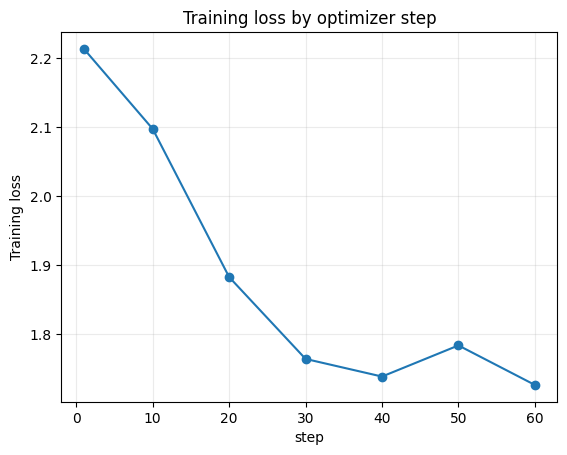

Final training loss: 1.8336
Post-SFT held-out loss: 1.7545
Trained LoRA-B norm: 8.834236
Completed optimizer steps: 63/63
Measured training runtime: 2.92 minutes
Peak allocated GPU memory during training: 4.54 GB


In [57]:
for stale_name in ["train_result", "baseline_eval_metrics", "post_eval_metrics", "trained_lora_b_norm", "training_history_df"]:
    globals().pop(stale_name, None)
if "trainer" in globals():
    del trainer
if "model" in globals():
    del model
if "train_model" in globals():
    del train_model
clear_memory()
compute_major, compute_minor = torch.cuda.get_device_capability(0)
use_bf16 = compute_major >= 8 and torch.cuda.is_bf16_supported()
training_dtype = torch.bfloat16 if use_bf16 else torch.float16
train_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=training_dtype, device_map="auto"
)
train_model.config.pad_token_id = tokenizer.pad_token_id
train_model.config.use_cache = False  # required with gradient checkpointing
print(f"Training precision: {'BF16' if use_bf16 else 'FP16'} (compute capability {compute_major}.{compute_minor})")
steps_per_epoch = math.ceil(math.ceil(len(formatted_dataset) / BATCH_SIZE) / GRAD_ACCUM_STEPS)
total_update_steps = steps_per_epoch * NUM_EPOCHS
warmup_steps = max(1, math.ceil(0.03 * total_update_steps))
sft_parameters = set(inspect.signature(SFTConfig).parameters)
sft_values = {
    "output_dir": OUTPUT_DIR,
    "num_train_epochs": NUM_EPOCHS,
    "per_device_train_batch_size": BATCH_SIZE,
    "per_device_eval_batch_size": BATCH_SIZE,
    "gradient_accumulation_steps": GRAD_ACCUM_STEPS,
    "learning_rate": LEARNING_RATE,
    "lr_scheduler_type": "cosine",
    "weight_decay": 0.01,
    "gradient_checkpointing": True,
    "gradient_checkpointing_kwargs": {"use_reentrant": False},
    "bf16": use_bf16,
    "fp16": not use_bf16,
    "max_length": MAX_SEQ_LENGTH,
    "logging_steps": 10,
    "logging_strategy": "steps",
    "logging_first_step": True,
    "include_num_input_tokens_seen": True,
    "save_strategy": "no",
    "report_to": "none",
    "seed": SEED,
    "data_seed": SEED,
    "packing": False,
}
if "warmup_ratio" in sft_parameters:
    sft_values["warmup_ratio"] = 0.03
elif "warmup_steps" in sft_parameters:
    sft_values["warmup_steps"] = warmup_steps
else:
    raise TypeError("Installed SFTConfig supports neither warmup_ratio nor warmup_steps.")
if "eval_strategy" in sft_parameters:
    sft_values["eval_strategy"] = "epoch"
elif "evaluation_strategy" in sft_parameters:
    sft_values["evaluation_strategy"] = "epoch"
if "max_length" not in sft_parameters and "max_seq_length" in sft_parameters:
    sft_values["max_seq_length"] = sft_values.pop("max_length")
unsupported_sft_fields = sorted(set(sft_values) - sft_parameters)
sft_values = {name: value for name, value in sft_values.items() if name in sft_parameters}
print(f"Optimizer steps: {total_update_steps}; warmup steps: {warmup_steps} (~3%)")
if unsupported_sft_fields:
    print("Optional fields not supported by this SFTConfig and omitted:", unsupported_sft_fields)
print("Applied SFTConfig fields:", sorted(sft_values))
training_args = SFTConfig(**sft_values)
assert bool(training_args.gradient_checkpointing), "Gradient checkpointing must be enabled."
assert bool(training_args.bf16) != bool(training_args.fp16), "Exactly one mixed-precision mode must be active."
assert bool(training_args.bf16) == use_bf16 and bool(training_args.fp16) == (not use_bf16)
precision_mode = "BF16" if training_args.bf16 else "FP16"
print(f"Gradient checkpointing verified: {training_args.gradient_checkpointing}")
print(f"Hardware-conditional mixed precision verified: {precision_mode}")
trainer = SFTTrainer(
    model=train_model,
    args=training_args,
    train_dataset=formatted_dataset,
    eval_dataset=eval_dataset,
    processing_class=tokenizer,
    peft_config=lora_config,
)
print_trainable_params(trainer.model)
baseline_eval_metrics = trainer.evaluate(metric_key_prefix="baseline")
print(f"Baseline held-out loss: {baseline_eval_metrics['baseline_loss']:.4f}")
torch.cuda.reset_peak_memory_stats()
training_started_at = time.perf_counter()
train_result = trainer.train()
training_runtime_seconds = time.perf_counter() - training_started_at
peak_gpu_memory_gb = torch.cuda.max_memory_allocated() / (1024 ** 3)
post_eval_metrics = trainer.evaluate(metric_key_prefix="post")
trained_lora_b_norm = sum(parameter.detach().float().norm().item() for name, parameter in trainer.model.named_parameters() if "lora_B" in name)
assert trained_lora_b_norm > 0, "LoRA B matrices did not change; training did not update the adapter."
completed_optimizer_steps = trainer.state.global_step
assert completed_optimizer_steps == total_update_steps, f"Expected {total_update_steps} optimizer steps, got {completed_optimizer_steps}."
assert math.isfinite(float(train_result.training_loss)), "Training loss is not finite."
training_history_df = pd.DataFrame(trainer.state.log_history)
diagnostic_columns = [column for column in ["step", "epoch", "loss", "eval_loss", "learning_rate", "grad_norm", "num_input_tokens_seen"] if column in training_history_df.columns]
display(training_history_df[diagnostic_columns].dropna(how="all"))
loss_rows = training_history_df.dropna(subset=["loss"]) if "loss" in training_history_df else pd.DataFrame()
if not loss_rows.empty:
    ax = loss_rows.plot(x="step", y="loss", marker="o", title="Training loss by optimizer step", legend=False)
    ax.set_ylabel("Training loss")
    ax.grid(alpha=0.25)
    plt.show()
print(f"Final training loss: {train_result.training_loss:.4f}")
print(f"Post-SFT held-out loss: {post_eval_metrics['post_loss']:.4f}")
print(f"Trained LoRA-B norm: {trained_lora_b_norm:.6f}")
print(f"Completed optimizer steps: {completed_optimizer_steps}/{total_update_steps}")
print(f"Measured training runtime: {training_runtime_seconds / 60:.2f} minutes")
print(f"Peak allocated GPU memory during training: {peak_gpu_memory_gb:.2f} GB")

---
## Stage 6: Adapter Persistence and Evaluation

### Task 7: Save the LoRA adapter and print its size

1. Save the trained model to `f"{OUTPUT_DIR}/final-adapter"`.
2. Also save the tokenizer to the same path.
3. Compute and print the adapter size in MB.

In [58]:
assert "train_result" in globals() and "post_eval_metrics" in globals(), "Training must finish successfully before saving the adapter."
assert trained_lora_b_norm > 0, "Refusing to save an untrained LoRA adapter."
trainer.model.save_pretrained(ADAPTER_DIR, safe_serialization=True)
tokenizer.save_pretrained(ADAPTER_DIR)
adapter_files = [p for p in Path(ADAPTER_DIR).iterdir() if p.name.startswith("adapter_")]
adapter_bytes = sum(p.stat().st_size for p in adapter_files)
bundle_bytes = sum(p.stat().st_size for p in Path(ADAPTER_DIR).iterdir() if p.is_file())
assert (Path(ADAPTER_DIR) / "adapter_config.json").exists()
assert any(p.name.startswith("adapter_model") for p in adapter_files)
print(f"Adapter saved to: {ADAPTER_DIR}")
print(f"LoRA adapter files: {adapter_bytes / 1024**2:.2f} MB")
print(f"Adapter + tokenizer bundle: {bundle_bytes / 1024**2:.2f} MB")
print("Saved files:", sorted(p.name for p in Path(ADAPTER_DIR).iterdir()))

Adapter saved to: ./sft-lora-tinyllama/final-adapter
LoRA adapter files: 4.31 MB
Adapter + tokenizer bundle: 7.77 MB
Saved files: ['README.md', 'adapter_config.json', 'adapter_model.safetensors', 'chat_template.jinja', 'tokenizer.json', 'tokenizer_config.json']


---
### 6.1 Side-by-side response comparison

### Task 8: Compare base vs fine-tuned responses

1. Use `trainer.model` (already has LoRA weights) to generate responses for the same `test_prompts`.
2. Print a side-by-side comparison of base vs fine-tuned responses.

In [59]:
assert "train_result" in globals(), "Training did not complete; fine-tuned evaluation is invalid."
assert tuple(test_prompts) == baseline_prompt_fingerprint, "Evaluation prompts changed after the baseline run."
assert GENERATION_SETTINGS == baseline_generation_settings, "Generation settings changed after the baseline run."
trainer.model.config.use_cache = True
fine_tuned_responses = [
    generate_response(trainer.model, tokenizer, prompt, baseline_generation_settings) for prompt in test_prompts
]
assert len(fine_tuned_responses) == len(base_responses) == len(test_prompts)
fair_comparison_verified = True
print("Fair comparison verified: identical prompts and deterministic generation settings.")
comparison_rows = []
for prompt, base, tuned in zip(test_prompts, base_responses, fine_tuned_responses):
    comparison_rows.extend([
        {"prompt": prompt, "model": "base", "response": base, **response_diagnostics(base)},
        {"prompt": prompt, "model": "LoRA-tuned", "response": tuned, **response_diagnostics(tuned)},
    ])
comparison_df = pd.DataFrame(comparison_rows)
pd.set_option("display.max_colwidth", 120)
display(comparison_df)
for prompt, base, tuned in zip(test_prompts, base_responses, fine_tuned_responses):
    print()
    print("PROMPT:", prompt)
    print("BASE:", base, sep="\n")
    print("FINE-TUNED:", tuned, sep="\n")
    print("-" * 100)

Fair comparison verified: identical prompts and deterministic generation settings.


,prompt,model,response,words,sentences,non_empty
0,Explain what a neural network is in 2-3 sentences.,base,A neural network is a type of artificial intelligence (AI) system that mimics the way the human brain processes info...,108,5,True
1,Explain what a neural network is in 2-3 sentences.,LoRA-tuned,A neural network is a mathematical model that simulates the functioning of the human brain. It is a type of artifici...,35,2,True
2,What are three tips for better sleep?,base,"1. Create a sleep-conducive environment: Make sure your bedroom is cool, dark, and quiet. Avoid using electronic dev...",93,13,True
3,What are three tips for better sleep?,LoRA-tuned,"1. Create a sleep-conducive environment: Turn off electronics, avoid caffeine and alcohol, and avoid smoking before ...",45,6,True



PROMPT: Explain what a neural network is in 2-3 sentences.
BASE:
A neural network is a type of artificial intelligence (AI) system that mimics the way the human brain processes information. It consists of a series of interconnected nodes (neurons) that receive input from other nodes and process and output information based on the input. Neural networks can be used for a variety of tasks, including image recognition, speech recognition, and machine translation. They are often trained using supervised learning, where the output of one node is used as input for the next node in the network. Neural networks are often used in deep learning, which involves training the network on large datasets to learn complex patterns and relationships.
FINE-TUNED:
A neural network is a mathematical model that simulates the functioning of the human brain. It is a type of artificial neural network that is designed to mimic the way the human brain processes information.
-------------------------------------

### 6.2 Quantitative held-out evaluation

Held-out cross-entropy is measured on 100 Dolly examples that were never used for training. Perplexity is `exp(loss)`; lower values mean the model assigns higher probability to the held-out conversational text. This complements the two-prompt qualitative comparison.

In [60]:
baseline_loss = float(baseline_eval_metrics["baseline_loss"])
post_loss = float(post_eval_metrics["post_loss"])
baseline_perplexity = math.exp(min(baseline_loss, 20))
post_perplexity = math.exp(min(post_loss, 20))
loss_delta = post_loss - baseline_loss
evaluation_summary = pd.DataFrame([{
    "metric": "Held-out Dolly",
    "base_loss": baseline_loss,
    "tuned_loss": post_loss,
    "loss_delta": loss_delta,
    "base_perplexity": baseline_perplexity,
    "tuned_perplexity": post_perplexity,
}])
display(evaluation_summary.round(4))
if loss_delta < 0:
    print(f"Held-out loss improved by {-loss_delta:.4f} ({-loss_delta / baseline_loss:.2%}).")
else:
    print(f"Held-out loss did not improve (delta {loss_delta:+.4f}); inspect the training log and qualitative outputs.")
assert comparison_df["non_empty"].all(), "Every generated response must be non-empty."
assert adapter_bytes < 100 * 1024**2, "Adapter is unexpectedly large for this LoRA configuration."

,metric,base_loss,tuned_loss,loss_delta,base_perplexity,tuned_perplexity
0,Held-out Dolly,2.2464,1.7545,-0.4919,9.4537,5.7808


Held-out loss improved by 0.4919 (21.90%).


### 6.3 Qualitative review rubric

For each before/after pair, review: (1) instruction compliance, (2) factual coherence, (3) relevance, (4) clarity, and (5) concision. Specifically verify that the neural-network answer uses 2–3 sentences and the sleep answer provides three distinct tips. Automated word/sentence counts are diagnostics, not substitutes for human judgment.

### 6.4 Clean adapter reload test

Saving is only useful if the lightweight artifact can be attached to a clean base model. This test frees the training objects, reloads TinyLlama, attaches the saved adapter with `PeftModel.from_pretrained`, and verifies deterministic output parity.

In [61]:
expected_reload_response = fine_tuned_responses[0]
del trainer, train_model
clear_memory()
reload_base = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME, dtype=training_dtype, device_map="auto"
)
reloaded_model = PeftModel.from_pretrained(reload_base, ADAPTER_DIR)
reloaded_model.config.pad_token_id = tokenizer.pad_token_id
reloaded_response = generate_response(reloaded_model, tokenizer, test_prompts[0], baseline_generation_settings)
assert reloaded_response == expected_reload_response, "Reloaded adapter output differs from the saved in-memory adapter."
print("Adapter reload verified.")
print(reloaded_response)

GPU allocated: 2.08 GB
GPU reserved:  4.12 GB


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Adapter reload verified.
A neural network is a mathematical model that simulates the functioning of the human brain. It is a type of artificial neural network that is designed to mimic the way the human brain processes information.


## Stage 7: Reproducibility Manifest and Submission Evidence

In [62]:
run_manifest = {
    "model_name": MODEL_NAME,
    "dataset_name": DATASET_NAME,
    "train_examples": len(formatted_dataset),
    "eval_examples": len(eval_dataset),
    "max_sequence_length": MAX_SEQ_LENGTH,
    "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT, "targets": LORA_TARGET_MODULES},
    "trainable_parameters": trainable_count,
    "trainable_percentage": trainable_percentage,
    "effective_batch_size": EFFECTIVE_BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "epochs": NUM_EPOCHS,
    "seed": SEED,
    "gradient_checkpointing": bool(training_args.gradient_checkpointing),
    "precision_mode": precision_mode,
    "compute_capability": f"{compute_major}.{compute_minor}",
    "optimizer_steps": {"expected": total_update_steps, "completed": completed_optimizer_steps},
    "training_runtime_seconds": training_runtime_seconds,
    "peak_gpu_memory_gb": peak_gpu_memory_gb,
    "fair_comparison_verified": fair_comparison_verified,
    "evaluation_prompts": list(test_prompts),
    "generation_settings": baseline_generation_settings,
    "training_loss": float(train_result.training_loss),
    "baseline_eval_loss": baseline_loss,
    "post_sft_eval_loss": post_loss,
    "adapter_size_mb": adapter_bytes / 1024**2,
    "packages": {name: metadata.version(name) for name in ["torch", "transformers", "trl", "peft", "datasets", "accelerate"]},
    "gpu": torch.cuda.get_device_name(0),
}
Path(OUTPUT_DIR).mkdir(parents=True, exist_ok=True)
with open(Path(OUTPUT_DIR) / "run_manifest.json", "w", encoding="utf-8") as handle:
    json.dump(run_manifest, handle, indent=2)
comparison_df.to_json(Path(OUTPUT_DIR) / "response_comparison.json", orient="records", indent=2)
training_history_df.to_csv(Path(OUTPUT_DIR) / "training_history.csv", index=False)
required_artifacts = [
    Path(ADAPTER_DIR) / "adapter_config.json",
    Path(ADAPTER_DIR) / "adapter_model.safetensors",
    Path(OUTPUT_DIR) / "run_manifest.json",
    Path(OUTPUT_DIR) / "response_comparison.json",
    Path(OUTPUT_DIR) / "training_history.csv",
]
missing_artifacts = [str(path) for path in required_artifacts if not path.is_file() or path.stat().st_size == 0]
assert not missing_artifacts, f"Missing or empty submission artifacts: {missing_artifacts}"
print("Final artifact assertions passed.")
print(json.dumps(run_manifest, indent=2))

Final artifact assertions passed.
{
  "model_name": "TinyLlama/TinyLlama-1.1B-Chat-v1.0",
  "dataset_name": "databricks/databricks-dolly-15k",
  "train_examples": 1000,
  "eval_examples": 100,
  "max_sequence_length": 512,
  "lora": {
    "r": 8,
    "alpha": 16,
    "dropout": 0.05,
    "targets": [
      "q_proj",
      "v_proj"
    ]
  },
  "trainable_parameters": 1126400,
  "trainable_percentage": 0.10229075496156657,
  "effective_batch_size": 16,
  "learning_rate": 0.0002,
  "epochs": 1,
  "seed": 42,
  "gradient_checkpointing": true,
  "precision_mode": "FP16",
  "compute_capability": "7.5",
  "optimizer_steps": {
    "expected": 63,
    "completed": 63
  },
  "training_runtime_seconds": 175.256048018,
  "peak_gpu_memory_gb": 4.541008472442627,
  "fair_comparison_verified": true,
  "evaluation_prompts": [
    "Explain what a neural network is in 2-3 sentences.",
    "What are three tips for better sleep?"
  ],
  "generation_settings": {
    "max_new_tokens": 160,
    "do_sample":

---
## Final Submission Checklist

1. Confirm the runtime reports a CUDA GPU and all package versions.
2. Confirm the dataset assertions pass and the train/eval sets contain 1,000/100 rows.
3. Confirm LoRA trainable parameters are below 1% and only `q_proj`/`v_proj` are trainable.
4. Confirm the Task 6 output explicitly verifies gradient checkpointing and the hardware-selected BF16/FP16 mode.
5. Review the stepwise loss/learning-rate diagnostics, runtime, completed optimizer steps, and peak GPU memory.
6. Confirm the comparison cell says the same prompts and deterministic generation settings were used for both models.
7. Confirm the adapter files are small, the clean reload test passes, and the final artifact assertion passes.
8. In Colab, choose **File → Save** after the final cell finishes, then download the notebook with all outputs visible.

The pipeline is complete when every assertion passes and the saved notebook contains fresh Colab outputs.